# LoRA: Low-Rank Adaptation (Hu et al., 2021)

Fine-tuning GPT-3 the ordinary way means updating all 175 billion weights and
saving a new 350 GB copy for every task. LoRA's observation is that the
*change* a fine-tune makes to a weight matrix has low **intrinsic rank**. You do
not need to learn a full $d \times k$ update. Two thin matrices whose product
has rank $r$ are enough:

$$h = W_0 x + \Delta W x = W_0 x + \frac{\alpha}{r} B A x,
\qquad B \in \mathbb{R}^{d \times r},\ A \in \mathbb{R}^{r \times k},\ r \ll \min(d, k)$$

$W_0$ is frozen. Only $A$ and $B$ train. $A$ starts random and $B$ starts at
**zero**, so at step 0 the adapted model is exactly the pre-trained one.

1. How many parameters this saves, from a 64-dim toy to GPT-3
2. A controlled test: a target update of rank 4, learned with r = 1 to 16
3. Does full fine-tuning produce low-rank updates on its own? An SVD check
4. Fine-tuning a small network on new classes: LoRA vs head-only vs full
5. Merging: zero extra inference latency, verified
6. QLoRA, and the knobs that matter in practice

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from hmw_motion import Scene, mix, diverge

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. The parameter arithmetic

A full update of a $d \times k$ matrix has $dk$ parameters. LoRA has
$r(d + k)$. For square matrices that is a fraction $2r/d$ of the original, so
the larger the model, the larger the saving.

The paper's headline setting is GPT-3 175B ($d_{model} = 12{,}288$, 96 layers)
with LoRA on only the query and value projections, at $r = 4$.

In [2]:
banner("TRAINABLE PARAMETERS")
for d in [64, 768, 4096, 12288]:
    for r in [4, 8]:
        print(f"  {d:>6} x {d:<6} full {d*d:>12,}   LoRA r={r}: {r*2*d:>8,}   ({100*2*r/d:6.3f}% of full)")
step("GPT-3 175B, LoRA on W_q and W_v in all 96 layers, r = 4")
d, L, r = 12288, 96, 4
lora = L * 2 * (r * 2 * d)
print(f"  trainable: 96 layers x 2 matrices x 4 x (12288 + 12288) = {lora:,}")
print(f"  saved per task in fp16: {lora*2/1e6:.1f} MB   vs  full model {175e9*2/1e9:.0f} GB")
print(f"  reduction in trainable parameters: {175e9/lora:,.0f}x")
print("  (paper: '10,000 times' fewer trainable parameters, checkpoint 350 GB -> 35 MB)")

  TRAINABLE PARAMETERS
      64 x 64     full        4,096   LoRA r=4:      512   (12.500% of full)
      64 x 64     full        4,096   LoRA r=8:    1,024   (25.000% of full)
     768 x 768    full      589,824   LoRA r=4:    6,144   ( 1.042% of full)
     768 x 768    full      589,824   LoRA r=8:   12,288   ( 2.083% of full)
    4096 x 4096   full   16,777,216   LoRA r=4:   32,768   ( 0.195% of full)
    4096 x 4096   full   16,777,216   LoRA r=8:   65,536   ( 0.391% of full)
   12288 x 12288  full  150,994,944   LoRA r=4:   98,304   ( 0.065% of full)
   12288 x 12288  full  150,994,944   LoRA r=8:  196,608   ( 0.130% of full)

GPT-3 175B, LoRA on W_q and W_v in all 96 layers, r = 4
------------------------------------------------------------------------------
  trainable: 96 layers x 2 matrices x 4 x (12288 + 12288) = 18,874,368
  saved per task in fp16: 37.7 MB   vs  full model 350 GB
  reduction in trainable parameters: 9,272x
  (paper: '10,000 times' fewer trainable parameters,

## 2. A controlled test: the update really is rank 4

To see what rank buys, build the situation LoRA assumes, where the truth is
known. A frozen "pre-trained" layer $W_0$ (64×64). A new task whose ideal weight
is $W_0 + \Delta W^*$, where $\Delta W^*$ has rank exactly 4, plus a little
full-rank noise. Then fine-tune it with full updates and with LoRA at ranks 1,
2, 4, 8 and 16.

The prediction is that ranks 1 to 3 cannot represent the update and plateau.
Rank 4 and above should remove essentially all of the error. The only part they
should miss is the small full-rank noise, which by construction only a full
update can fit.

  LEARNING A RANK-4 UPDATE
  singular values of the true update: [6.568 5.051 3.925 2.824 0.    0.   ]
  validation MSE of the frozen pre-trained layer: 1.42505

LoRA starts as an exact copy of the pre-trained layer (B = 0)
------------------------------------------------------------------------------
  [PASS] LoRA output at step 0 == W0 x

Validation MSE after 1,500 steps
------------------------------------------------------------------------------
  full        trainable 4,096   MSE 0.000000   (  0.00% of the frozen layer's error)
  LoRA r=1    trainable   128   MSE 0.765971   ( 53.75% of the frozen layer's error)
  LoRA r=2    trainable   256   MSE 0.369708   ( 25.94% of the frozen layer's error)
  LoRA r=4    trainable   512   MSE 0.000091   (  0.01% of the frozen layer's error)
  LoRA r=8    trainable 1,024   MSE 0.000086   (  0.01% of the frozen layer's error)
  LoRA r=16   trainable 2,048   MSE 0.000075   (  0.01% of the frozen layer's error)
  [PASS] rank 1-3 cannot fit a rank

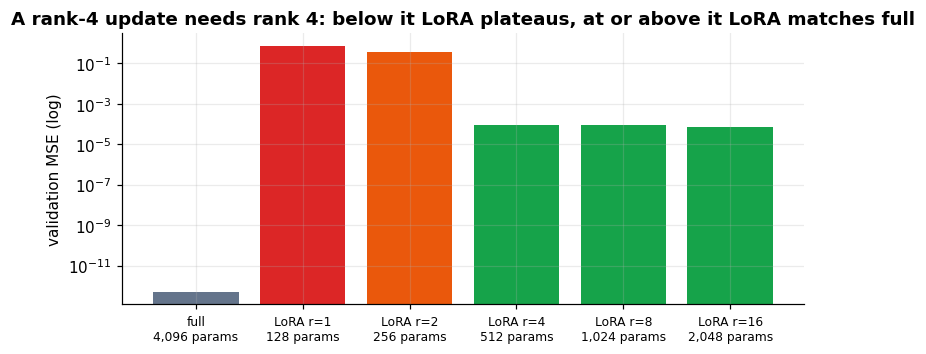

In [3]:
banner("LEARNING A RANK-4 UPDATE")
D = 64
g = torch.Generator().manual_seed(1)
W0 = torch.randn(D, D, generator=g) / D ** 0.5
U_, V_ = torch.randn(D, 4, generator=g), torch.randn(4, D, generator=g)
dW_true = 0.6 * (U_ @ V_) / D ** 0.5
N_noise = 0.01 * torch.randn(D, D, generator=g) / D ** 0.5      # small, full-rank
W_task = W0 + dW_true + N_noise
X = torch.randn(4000, D, generator=g)
Y = X @ W_task.T
Xv = torch.randn(1000, D, generator=g); Yv = Xv @ W_task.T
print(f"  singular values of the true update: {torch.linalg.svdvals(dW_true)[:6].numpy().round(3)}")


class LoRALinear(nn.Module):
    def __init__(self, W0, r, alpha=None):
        super().__init__()
        self.W0 = nn.Parameter(W0.clone(), requires_grad=False)
        self.r, self.scale = r, (alpha or r) / r
        self.A = nn.Parameter(torch.randn(r, W0.shape[1]) / W0.shape[1] ** 0.5)
        self.B = nn.Parameter(torch.zeros(W0.shape[0], r))

    def delta(self):
        return self.scale * self.B @ self.A

    def forward(self, x):
        return x @ self.W0.T + self.scale * (x @ self.A.T) @ self.B.T


def train(model, params, steps=1500, lr=1e-2, snap=None, every=60, at=None):
    opt = torch.optim.Adam(params, lr=lr)
    for it in range(steps):
        idx = torch.randint(0, len(X), (256,), generator=g)
        loss = F.mse_loss(model(X[idx]), Y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        hit = (it in at) if at is not None else (it % every == 0)
        if snap is not None and (hit or it == steps - 1):
            snap(it)
    with torch.no_grad():
        return F.mse_loss(model(Xv), Yv).item()


base_loss = F.mse_loss(Xv @ W0.T, Yv).item()
print(f"  validation MSE of the frozen pre-trained layer: {base_loss:.5f}")

step("LoRA starts as an exact copy of the pre-trained layer (B = 0)")
probe = LoRALinear(W0, 4)
check("LoRA output at step 0 == W0 x", torch.allclose(probe(Xv), Xv @ W0.T))

results = {}
full = nn.Linear(D, D, bias=False)
with torch.no_grad():
    full.weight.copy_(W0)
full_snaps = []
results["full"] = (train(full, full.parameters(), lr=3e-3,
                         snap=lambda it: full_snaps.append((it, torch.linalg.svdvals(full.weight.detach() - W0)[:16].numpy())),
                         at=set(np.unique(np.geomspace(1, 1499, 22).astype(int)))),
                   D * D)
lora_models = {}
lora_snaps = []
for r in [1, 2, 4, 8, 16]:
    m = LoRALinear(W0, r)
    snapfn = (lambda it, m=m: lora_snaps.append((it, m.B.detach().clone(), m.A.detach().clone()))) if r == 2 else None
    results[f"LoRA r={r}"] = (train(m, [m.A, m.B], snap=snapfn, every=150), r * 2 * D)
    lora_models[r] = m
step("Validation MSE after 1,500 steps")
for k, (loss, n) in results.items():
    print(f"  {k:<11} trainable {n:>5,}   MSE {loss:.6f}   ({loss/base_loss*100:6.2f}% of the frozen layer's error)")
check("rank 1-3 cannot fit a rank-4 update: r=2 error is > 10x the r=4 error",
      results["LoRA r=2"][0] > 10 * results["LoRA r=4"][0])
noise_mse = F.mse_loss(Xv @ N_noise.T, torch.zeros_like(Yv)).item()
print()
print(f"  error contributed by the full-rank noise term alone: {noise_mse:.6f}")
check("r >= 4 removes > 99.9% of the frozen layer's error", results["LoRA r=4"][0] < 1e-3 * base_loss)
check("what r = 4 leaves is the full-rank noise, which no rank-4 update can express (within 20%)",
      abs(results["LoRA r=4"][0] - noise_mse) < 0.2 * noise_mse)

fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(results)
ax.bar(range(len(names)), [results[k][0] for k in names],
       color=["#64748b"] + ["#dc2626", "#ea580c", "#16a34a", "#16a34a", "#16a34a"])
ax.set_yscale("log"); ax.set_xticks(range(len(names))); ax.set_xticklabels(
    [f"{k}\n{results[k][1]:,} params" for k in names], fontsize=8)
ax.set_ylabel("validation MSE (log)"); ax.set_title("A rank-4 update needs rank 4: below it LoRA plateaus, at or above it LoRA matches full")

LoRA as a picture: a frozen matrix, and next to it two thin trainable
matrices whose product is the update. The cells below are the top-left 12×12
corner of the real $W_0$, with the first 12 rows of $B$ and the first 12
columns of $A$ from the $r = 2$ run above, frame by frame as they train.

In [4]:
def lora_scene():
    n = 12
    W0c = W0[:n, :n].numpy()
    sc = Scene(720, 400, dur=12.0, caption="LoRA (r = 2) training on the toy task: W0 frozen, only B and A move",
               poster=11.0)
    cs = 17
    vmax = np.abs(W0c).max()
    ox, oy = 30, 70
    sc.text(ox + n * cs / 2, 50, "W0 (frozen)", size=13, fill="muted")
    w_cells = [[sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2, fill=diverge(W0c[i, j], vmax), rx=2)
                for j in range(n)] for i in range(n)]
    sc.text(ox + n * cs + 22, oy + n * cs / 2, "+", size=26, fill="text")
    bx = ox + n * cs + 46
    sc.text(bx + cs, 50, "B", size=14, fill="cyan", weight=700)
    ax_ = bx + 2 * cs + 30
    sc.text(ax_ + n * cs / 2, 50, "A", size=14, fill="pink", weight=700)
    sc.text(ax_ + n * cs / 2, oy + 2 * cs + 30, "B starts at zero, so B A = 0 at step 0", size=11, fill="muted")
    _, B_last, A_last = lora_snaps[-1]
    bmax = np.abs(B_last[:n].numpy()).max(); amax = np.abs(A_last[:, :n].numpy()).max()
    b_cells = [[sc.rect(bx + j * cs, oy + i * cs, cs - 2, cs - 2, fill=diverge(0, 1), rx=2) for j in range(2)]
               for i in range(n)]
    a_cells = [[sc.rect(ax_ + j * cs, oy + i * cs, cs - 2, cs - 2, fill=diverge(lora_snaps[0][2][i, j].item(), amax),
                        rx=2) for j in range(n)] for i in range(2)]
    dx = ax_
    dy = oy + 4 * cs + 40
    sc.text(dx + n * cs / 2, dy - 14, "update  B A  (rank 2)", size=12, fill="amber")
    dmax = np.abs((lora_models[2].delta()[:n, :n]).detach().numpy()).max()
    d_cells = [[sc.rect(dx + j * cs * 0.75, dy + i * cs * 0.75, cs * 0.75 - 2, cs * 0.75 - 2, fill=diverge(0, 1), rx=2)
                for j in range(n)] for i in range(n)]
    it_num = sc.num(ox, 330, 0, dec=0, pre="step ", size=14, fill="amber", anchor="start")
    sc.text(ox, 356, f"trainable here: B {n}x2 + A 2x{n} = {4*n} numbers vs {n*n} for a full update",
            size=12, fill="muted", anchor="start")
    T0, T1 = 0.6, 9.0
    for k, (it, Bk, Ak) in enumerate(lora_snaps):
        t = T0 + (T1 - T0) * k / (len(lora_snaps) - 1)
        Bk, Ak = Bk.numpy(), Ak.numpy()
        Dk = (Bk @ Ak)[:n, :n]
        for i in range(n):
            for j in range(2):
                b_cells[i][j].to(max(0, t - 0.35), t, fill=diverge(Bk[i, j], bmax), ease="lin")
        for i in range(2):
            for j in range(n):
                a_cells[i][j].to(max(0, t - 0.35), t, fill=diverge(Ak[i, j], amax), ease="lin")
        for i in range(n):
            for j in range(n):
                d_cells[i][j].to(max(0, t - 0.35), t, fill=diverge(Dk[i, j], dmax), ease="lin")
        it_num.to(max(0, t - 0.35), t, v=it + 1, ease="lin")
    merged = (W0[:n, :n] + lora_models[2].delta()[:n, :n]).detach().numpy()
    for i in range(n):
        for j in range(n):
            w_cells[i][j].to(10.0, 10.8, fill=diverge(merged[i, j], vmax))
    sc.beat(0.0, "Only the 2-column B and the 2-row A receive gradients. W0 never changes.")
    sc.beat(3.5, "Their product is a full-size update, but every row of it is a mix of just 2 patterns.")
    sc.beat(10.0, "For inference, add B A into W0 once: the same speed as the original layer.")
    return sc

lora_scene()

<motion scene: LoRA (r = 2) training on the toy task: W0 frozen, only B and A move (344 elements, 12s)>

## 3. Does full fine-tuning find a low-rank update by itself?

The paper's justification goes further than "low rank is enough". It argues
that the updates found by ordinary fine-tuning are *themselves* close to low
rank. On the toy task, take the update full fine-tuning learned,
$W_{\text{final}} - W_0$, and look at its singular values as training
progresses.

In [5]:
banner("SINGULAR VALUES OF THE FULL FINE-TUNING UPDATE")
sv_final = full_snaps[-1][1]
all_sv = torch.linalg.svdvals(full.weight.detach() - W0).numpy()
energy = np.cumsum(all_sv ** 2) / np.sum(all_sv ** 2)
print(f"  top 8 singular values: {all_sv[:8].round(4)}")
print(f"  share of the update's energy in the top 1/2/4/8 directions: "
      f"{energy[0]:.3f} / {energy[1]:.3f} / {energy[3]:.3f} / {energy[7]:.3f}")
check("over 99% of the full update lies in 4 of 64 directions", energy[3] > 0.99)

sc = Scene(720, 330, dur=9.5, caption="Full fine-tuning on the toy task: the top 16 singular values of W - W0",
           poster=9.0)
bw = 34
base = 270
smax = max(s[1].max() for s in full_snaps)
bars = [sc.rect(60 + i * (bw + 6), base, bw, 0, fill="violet" if i >= 4 else "cyan", rx=3) for i in range(16)]
for i in range(16):
    sc.text(60 + i * (bw + 6) + bw / 2, base + 16, f"σ{i+1}", size=11, fill="muted")
itn = sc.num(690, 40, 0, dec=0, pre="step ", size=14, fill="amber", anchor="end")
for k, (it, svs) in enumerate(full_snaps):
    t = 0.5 + 8.0 * k / (len(full_snaps) - 1)
    for i in range(16):
        h = svs[i] / smax * 210
        bars[i].to(max(0, t - 0.3), t, h=h, y=base - h, ease="lin")
    itn.to(max(0, t - 0.3), t, v=it + 1, ease="lin")
sc.text(60 + 2 * (bw + 6), 40, "the 4 directions of the true update", size=12, fill="cyan")
sc.beat(0.0, "Full fine-tuning is free to change all 64 directions of the matrix.")
sc.beat(3.0, "It still ends up moving almost entirely along 4 of them...")
sc.beat(6.0, "...so a rank-4 LoRA can express what the full update learned.")
sc

  SINGULAR VALUES OF THE FULL FINE-TUNING UPDATE
  top 8 singular values: [6.5659 5.0522 3.9252 2.8259 0.0193 0.0179 0.0171 0.017 ]
  share of the update's energy in the top 1/2/4/8 directions: 0.468 / 0.746 / 1.000 / 1.000
  [PASS] over 99% of the full update lies in 4 of 64 directions


<motion scene: Full fine-tuning on the toy task: the top 16 singular values of W - W0 (34 elements, 9.5s)>

That was a constructed case, where the truth was rank 4 by design. A more
realistic test is a small network pre-trained on one task and fine-tuned on
another. Here a 2-hidden-layer MLP is pre-trained on handwritten digits 0 to 4,
then adapted to tell apart digits 5 to 9, which it has never seen. Each method
gets a fresh output head:

* **Head only**: freeze the whole body
* **LoRA r = 1, 2, 4, 8** on both hidden layers, plus the head
* **Full fine-tuning** of everything

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

banner("PRE-TRAIN ON 0-4, ADAPT TO 5-9")
dg = load_digits()
Xd = torch.tensor(dg.data / 16.0, dtype=torch.float32); yd = torch.tensor(dg.target)
pre, new = yd < 5, yd >= 5
Xp, yp = Xd[pre], yd[pre]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xd[new], yd[new] - 5, test_size=0.5, random_state=0,
                                              stratify=yd[new])
Xn_tr, yn_tr = Xn_tr[:150], yn_tr[:150]          # a small labelled set, as in fine-tuning
print(f"  pre-training set: {len(Xp)} images of 0-4   fine-tuning set: {len(Xn_tr)}   test: {len(Xn_te)}")


class Body(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1, self.l2 = nn.Linear(64, 128), nn.Linear(128, 128)

    def forward(self, x):
        return F.relu(self.l2(F.relu(self.l1(x))))


torch.manual_seed(0)
body = Body(); head0 = nn.Linear(128, 5)
opt = torch.optim.Adam(list(body.parameters()) + list(head0.parameters()), lr=2e-3)
for it in range(600):
    idx = torch.randint(0, len(Xp), (128,))
    loss = F.cross_entropy(head0(body(Xp[idx])), yp[idx])
    opt.zero_grad(); loss.backward(); opt.step()
print(f"  pre-trained accuracy on 0-4 (train set): {(head0(body(Xp)).argmax(1) == yp).float().mean():.3f}")
state0 = {k: v.clone() for k, v in body.state_dict().items()}


class LoRABody(nn.Module):
    def __init__(self, r):
        super().__init__()
        self.b = Body(); self.b.load_state_dict(state0)
        for p in self.b.parameters():
            p.requires_grad = False
        self.A1, self.B1 = nn.Parameter(torch.randn(r, 64) / 8), nn.Parameter(torch.zeros(128, r))
        self.A2, self.B2 = nn.Parameter(torch.randn(r, 128) / 128 ** .5), nn.Parameter(torch.zeros(128, r))

    def forward(self, x):
        h = F.relu(self.b.l1(x) + x @ self.A1.T @ self.B1.T)
        return F.relu(self.b.l2(h) + h @ self.A2.T @ self.B2.T)


def finetune(mode, r=None, seed=0):
    torch.manual_seed(seed)
    head = nn.Linear(128, 5)
    if mode == "lora":
        m = LoRABody(r); params = [m.A1, m.B1, m.A2, m.B2]
    else:
        m = Body(); m.load_state_dict(state0)
        params = list(m.parameters()) if mode == "full" else []
        if mode == "head":
            for p in m.parameters():
                p.requires_grad = False
    params = params + list(head.parameters())
    opt = torch.optim.Adam(params, lr=3e-3)
    for it in range(400):
        idx = torch.randint(0, len(Xn_tr), (64,))
        loss = F.cross_entropy(head(m(Xn_tr[idx])), yn_tr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = (head(m(Xn_te)).argmax(1) == yn_te).float().mean().item()
    n_tr = sum(p.numel() for p in params)
    return acc, n_tr, m


rows = [("head only", "head", None)] + [(f"LoRA r={r}", "lora", r) for r in [1, 2, 4, 8]] + [("full", "full", None)]
dig = {}
for name, mode, r in rows:
    accs = [finetune(mode, r, s)[0] for s in range(3)]
    _, n_tr, m = finetune(mode, r, 0)
    dig[name] = (np.mean(accs), np.std(accs), n_tr, m)
    print(f"  {name:<10} trainable {n_tr:>6,}   test accuracy on 5-9: {np.mean(accs):.3f} ± {np.std(accs):.3f}  (3 seeds)")
check("LoRA r=4 beats head-only", dig["LoRA r=4"][0] > dig["head only"][0])

full_m = dig["full"][3]
dW1 = (full_m.l2.weight - state0["l2.weight"]).detach()
sv = torch.linalg.svdvals(dW1).numpy()
en = np.cumsum(sv ** 2) / (sv ** 2).sum()
print(f"\n  full fine-tune, layer 2 update: energy in top 4 / 8 / 16 of 128 directions = "
      f"{en[3]:.3f} / {en[7]:.3f} / {en[15]:.3f}")

  PRE-TRAIN ON 0-4, ADAPT TO 5-9
  pre-training set: 901 images of 0-4   fine-tuning set: 150   test: 448
  pre-trained accuracy on 0-4 (train set): 1.000
  head only  trainable    645   test accuracy on 5-9: 0.760 ± 0.008  (3 seeds)
  LoRA r=1   trainable  1,093   test accuracy on 5-9: 0.940 ± 0.011  (3 seeds)
  LoRA r=2   trainable  1,541   test accuracy on 5-9: 0.952 ± 0.003  (3 seeds)
  LoRA r=4   trainable  2,437   test accuracy on 5-9: 0.967 ± 0.003  (3 seeds)
  LoRA r=8   trainable  4,229   test accuracy on 5-9: 0.966 ± 0.005  (3 seeds)
  full       trainable 25,477   test accuracy on 5-9: 0.975 ± 0.002  (3 seeds)
  [PASS] LoRA r=4 beats head-only

  full fine-tune, layer 2 update: energy in top 4 / 8 / 16 of 128 directions = 0.902 / 0.971 / 0.989


The realistic case is less clean than the constructed one, and the numbers say
so. Full fine-tuning's update is concentrated but not rank 4. LoRA at small
ranks recovers most of the gap between "head only" and "full fine-tuning", and
the paper's GPT-3 experiments show the same: $r$ as small as 1 to 4 on the
attention projections came close to full fine-tuning on most benchmarks, and
sometimes beat it.

## 5. Merging: no added latency

Adapters add layers, and therefore time, to every forward pass. LoRA does not
have to. After training, compute $W = W_0 + \frac{\alpha}{r}BA$ once, and the
model is an ordinary model again. To switch tasks, subtract one update and add
another.

In [7]:
banner("MERGE, THEN UNMERGE")
m = lora_models[4]
with torch.no_grad():
    unmerged = m(Xv)
    W_merged = m.W0 + m.delta()
    merged = Xv @ W_merged.T
    W_back = W_merged - m.delta()
check("merged layer output == W0 x + scale * B A x", torch.allclose(merged, unmerged, atol=1e-5))
check("subtracting the update recovers W0 exactly (to float precision)", torch.allclose(W_back, m.W0, atol=1e-6))
print(f"  matmuls per forward pass: unmerged 3 (W0, A, B), merged 1")

  MERGE, THEN UNMERGE
  [PASS] merged layer output == W0 x + scale * B A x
  [PASS] subtracting the update recovers W0 exactly (to float precision)
  matmuls per forward pass: unmerged 3 (W0, A, B), merged 1


## 6. QLoRA and the knobs that matter

**QLoRA** (Dettmers et al., 2023) stores the frozen $W_0$ in 4-bit NormalFloat
and trains LoRA adapters in 16-bit on top. Because the base weights never
change, quantising them costs little, and the paper fine-tuned a 65B model on a
single 48 GB GPU.

In practice:

* **Which matrices.** The paper used $W_q$ and $W_v$. Common practice now
  applies LoRA to all linear layers, including the MLP, which usually helps more
  than raising $r$.
* **Rank $r$**: 8 to 64 is typical. The toy test shows why too low a rank
  plateaus. Beyond the update's real rank, extra rank adds parameters and
  little else.
* **$\alpha$**: the update is scaled by $\alpha / r$, so changing $r$ does not
  silently change the effective learning rate. A common default is $\alpha = 2r$.
* **Initialisation**: $B = 0$ is not optional. It is what makes step 0 identical
  to the pre-trained model.

## Summary

* LoRA freezes $W_0$ and learns $\Delta W = \frac{\alpha}{r} BA$, which has
  $r(d+k)$ parameters instead of $dk$. For GPT-3 at $r = 4$ on $W_q, W_v$
  that is 18.9M trainable parameters, about 9,000× fewer, and a checkpoint of
  about 38 MB.
* When the needed update has rank 4, LoRA at rank 1 to 2 plateaus. Rank 4
  removes 99.99% of the error, and what remains is exactly the full-rank part
  no rank-4 update can express. This is measured, not assumed.
* Full fine-tuning concentrates its update in a few directions: 100% of the
  energy in 4 directions in the constructed case, and 90% in 4 of 128 in the
  digits network. On new digit classes, LoRA r = 4 reached 96.7% against 97.5%
  for full fine-tuning and 76% for the head alone, with a tenth of the
  trainable parameters.
* Merged LoRA adds zero inference cost, and unmerging switches tasks.